<a href="https://colab.research.google.com/github/Chandsi-06/NNDL_Practicals/blob/main/NNDL_7_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Loading model...
Model loaded successfully!
      0/Unknown 0s 0s/step

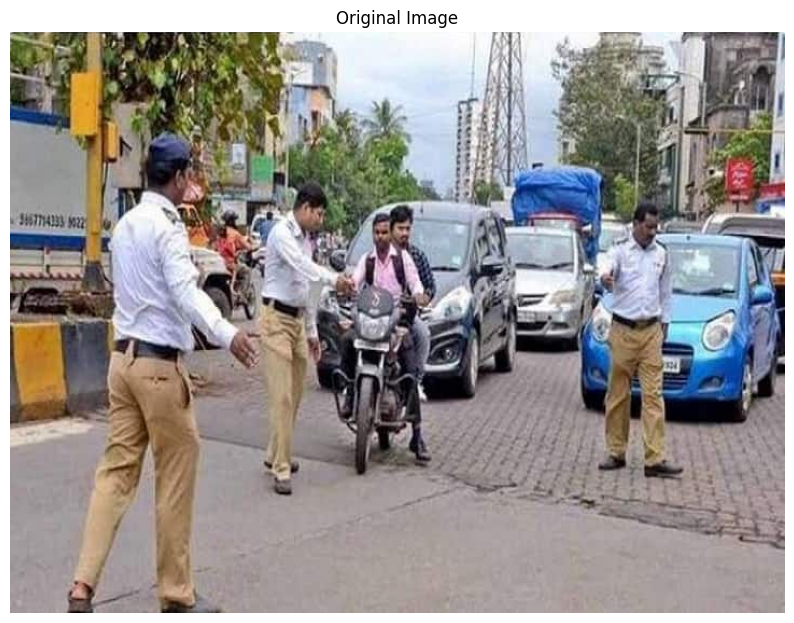

Detected 100 objects.


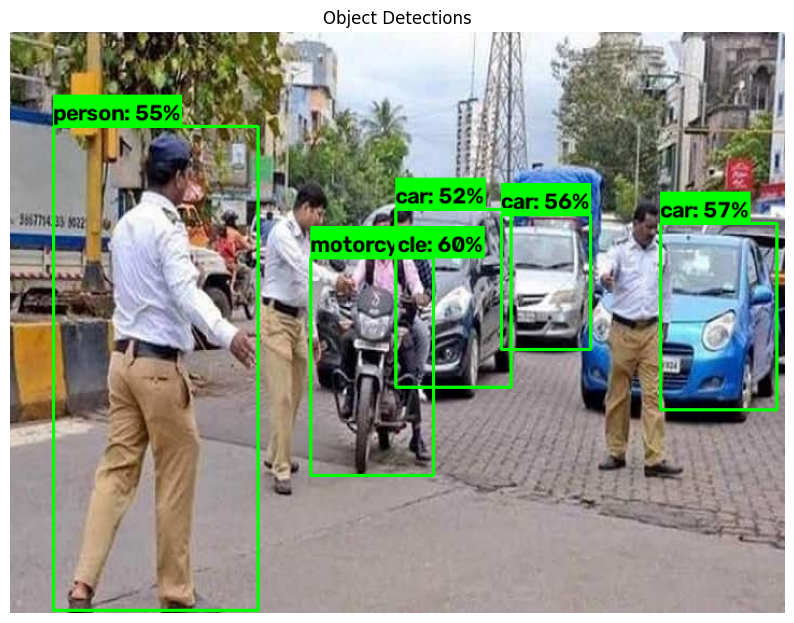

In [2]:
# Install necessary libraries
!pip install opencv-python tensorflow_hub matplotlib
import tensorflow as tf
import tensorflow_hub as hub
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the pre-trained SSD MobileNet V2 model
print("Loading model...")
detector = hub.load("https://tfhub.dev/tensorflow/ssd_mobilenet_v2/fpnlite_320x320/1")
print("Model loaded successfully!")

# Function to load image from URL
def load_image_from_url(image_url):
    image_path = tf.keras.utils.get_file(origin=image_url)
    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image_np = np.array(image_rgb)
    return image_np

# Sample image URL
image_url = "https://feeds.abplive.com/onecms/images/uploaded-images/2022/06/08/cba50dc1f15b89efcce65f6a9ec7350b_original.JPG"
image_np = load_image_from_url(image_url)

# Display original image
plt.figure(figsize=(10, 8))
plt.imshow(image_np)
plt.axis('off')
plt.title('Original Image')
plt.show()

# Prepare input tensor
input_tensor = tf.convert_to_tensor(image_np)
input_tensor = input_tensor[tf.newaxis, ...]

# Perform inference
result = detector(input_tensor)

# Convert results to NumPy
result = {key: value.numpy() for key, value in result.items()}

# Extract detection results
boxes = result['detection_boxes'][0]
scores = result['detection_scores'][0]
class_ids = result['detection_classes'][0]
num_detections = int(result['num_detections'][0])
print(f"Detected {num_detections} objects.")

# Function to draw boxes and labels
def draw_boxes_and_labels(image, boxes, classes, scores, num_detections, category_index, min_score_thresh=0.5):
    image_copy = np.copy(image)
    im_height, im_width, _ = image_copy.shape
    for i in range(num_detections):
        if scores[i] > min_score_thresh:
            ymin, xmin, ymax, xmax = boxes[i]
            ymin = int(ymin * im_height)
            xmin = int(xmin * im_width)
            ymax = int(ymax * im_height)
            xmax = int(xmax * im_width)
            class_name = category_index.get(int(classes[i]), {'name': 'N/A'})['name']
            label = f'{class_name}: {int(scores[i] * 100)}%'

            # Draw bounding box
            cv2.rectangle(image_copy, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)

            # Draw label background
            (w, h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
            cv2.rectangle(image_copy, (xmin, ymin - h - 10), (xmin + w, ymin), (0, 255, 0), -1)
            cv2.putText(image_copy, label, (xmin, ymin - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
    return image_copy

# COCO class names
category_index = {
    1: {'id': 1, 'name': 'person'},
    2: {'id': 2, 'name': 'bicycle'},
    3: {'id': 3, 'name': 'car'},
    4: {'id': 4, 'name': 'motorcycle'},
    5: {'id': 5, 'name': 'airplane'},
    15: {'id': 15, 'name': 'cat'},
    16: {'id': 16, 'name': 'dog'},
    17: {'id': 17, 'name': 'horse'},
    18: {'id': 18, 'name': 'sheep'},
    19: {'id': 19, 'name': 'cow'},
    20: {'id': 20, 'name': 'elephant'},
    21: {'id': 21, 'name': 'bear'}
}

# Draw detection results
image_with_detections = draw_boxes_and_labels(
    image_np,
    boxes,
    class_ids,
    scores,
    num_detections,
    category_index
)

# Display detections
plt.figure(figsize=(10, 8))
plt.imshow(image_with_detections)
plt.axis('off')
plt.title('Object Detections')
plt.show()